In [ ]:
print("hello Helena")

hello Helena


In [ ]:
from google.colab import userdata
from googleapiclient.discovery import build

API_KEY = userdata.get("YT_API_KEY")
youtube = build("youtube", "v3", developerKey=API_KEY)

response = youtube.videos().list(part="snippet,statistics", id="ygwbT4bLu0I").execute()
video = response["items"][0]

print("Title:", video["snippet"]["title"])
print("Number of comments:", video["statistics"].get("commentCount"))

Title: Real-time cutscenes can be hilarious 💀 #thelastofus #gaming
Number of comments: 2444


In [ ]:
from google.colab import files
import pandas as pd
import re

uploaded = files.upload()
filename = list(uploaded.keys())[0]
ids_df = pd.read_csv(filename)
ids_df = ids_df.dropna(subset=["video_id"])

def clean_id(text):
    text = str(text).strip()
    match = re.search(r"(?:shorts/|v=|youtu\.be/)([A-Za-z0-9_-]{11})", text)
    if match:
        return match.group(1)
    return text

ids_df["video_id"] = ids_df["video_id"].apply(clean_id)
video_ids = ids_df["video_id"].unique().tolist()

print("Rows in your sheet:", len(ids_df))
print("Unique video IDs:", len(video_ids))
print("First 3:", video_ids[:3])
print("IDs that don't look right:", [v for v in video_ids if len(v) != 11])

Saving YouTube Shorts APIs - Sheet1(2).csv to YouTube Shorts APIs - Sheet1(2).csv
Rows in your sheet: 250
Unique video IDs: 250
First 3: ['ygwbT4bLu0I', '_efkH42nxCA', 'fQRbkvMBuqE']
IDs that don't look right: []


In [ ]:
from googleapiclient.errors import HttpError

MAX_COMMENTS_PER_VIDEO = 10

all_comments = []
problems = []

for i, vid in enumerate(video_ids, start=1):
    collected = 0
    page_token = None
    try:
        while collected < MAX_COMMENTS_PER_VIDEO:
            response = youtube.commentThreads().list(
                part="snippet",
                videoId=vid,
                maxResults=100,
                order="relevance",
                textFormat="plainText",
                pageToken=page_token,
            ).execute()
            for item in response["items"]:
                top = item["snippet"]["topLevelComment"]["snippet"]
                all_comments.append({
                    "video_id": vid,
                    "comment_id": item["id"],
                    "text": top["textDisplay"],
                    "likes": top["likeCount"],
                    "published_at": top["publishedAt"],
                    "reply_count": item["snippet"]["totalReplyCount"],
                })
                collected += 1
                if collected >= MAX_COMMENTS_PER_VIDEO:
                    break
            page_token = response.get("nextPageToken")
            if not page_token:
                break
    except HttpError as e:
        problems.append({"video_id": vid, "problem": str(e)[:150]})
    if i % 25 == 0:
        print(f"Done {i} of {len(video_ids)} videos... {len(all_comments)} comments so far")

comments_df = pd.DataFrame(all_comments)
comments_df.to_csv("comments_raw.csv", index=False)

print("Total comments:", len(comments_df))
print("Videos with comments:", comments_df["video_id"].nunique())
print("Videos with problems:", len(problems))
for p in problems:
    print(p)

Done 25 of 250 videos... 235 comments so far
Done 50 of 250 videos... 462 comments so far
Done 75 of 250 videos... 677 comments so far
Done 100 of 250 videos... 833 comments so far
Done 125 of 250 videos... 979 comments so far
Done 150 of 250 videos... 1108 comments so far


Done 175 of 250 videos... 1273 comments so far


Done 200 of 250 videos... 1456 comments so far
Done 225 of 250 videos... 1645 comments so far
Done 250 of 250 videos... 1818 comments so far
Total comments: 1818
Videos with comments: 227
Videos with problems: 2
{'video_id': 'c1boOi4RXzs', 'problem': '<HttpError 403 when requesting https://youtube.googleapis.com/youtube/v3/commentThreads?part=snippet&videoId=c1boOi4RXzs&maxResults=100&order=relevanc'}
{'video_id': 'Kwn82syyekQ', 'problem': '<HttpError 403 when requesting https://youtube.googleapis.com/youtube/v3/commentThreads?part=snippet&videoId=Kwn82syyekQ&maxResults=100&order=relevanc'}


In [ ]:
files.download("comments_raw.csv")
comments_df.sample(10, random_state=1)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,video_id,comment_id,text,likes,published_at,reply_count
1413,J9_stwbP37o,UgwYa6MjyKaJkEQN3VN4AaABAg,Pretty sure scalp dust still falls off ya skin,1640,2026-10-05T00:37:20Z,47
1498,GFxy_iy4cdA,Ugx46xUrf3-6AYmrAmV4AaABAg,he was js checking if he rushes in the smoke o...,1,2026-09-08T08:10:05Z,0
507,01VnVAcRCEI,UgxvIqyU9yh3N1FyNtZ4AaABAg,When my staffie was a puppy his teeth were so...,3843,2026-08-25T00:55:22Z,19
408,m_m3H5NzTfo,UgyQ9EGFmBaR0SOjz1B4AaABAg,"Redbull: ""Alright, good plan. However, we shou...",0,2026-10-04T02:18:30Z,0
622,2phgJGo9fv4,Ugw0igwK2bEzKrAAjqN4AaABAg,Espectacular imagen felicidades por demostrar ...,1,2026-10-23T21:42:25Z,0
231,sbmecrSlozA,UgyEPcgwggdH1XtiQyF4AaABAg,😢the way her smile faded away without him,7,2026-10-23T18:22:50Z,0
161,ZvmfD6XwS1U,UgwDhYdPermTl077kH14AaABAg,Don't forget your first born still a baby that...,6135,2026-09-02T13:47:52Z,12
575,Nf6RnVybKTM,UgxqJxvuBcygOIjHEmN4AaABAg,I think he just got stuck in the container,31,2026-10-19T03:40:40Z,3
1000,3tvyjjze5yA,UgzXfVzskVwYOFfgtzx4AaABAg,Schools teach to the LOWEST common denominator...,0,2026-10-24T03:30:20Z,0
1165,BMDfHlibeI8,Ugyj6TketsQWy6EcX-R4AaABAg,2016 : try Not to laugh\n2026: try to understand,5611,2026-10-12T10:31:15Z,19


In [ ]:
import torch
from transformers import pipeline

print("GPU available:", torch.cuda.is_available())

sentiment = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if torch.cuda.is_available() else -1,
)

print(sentiment("this made my day 😂"))
print(sentiment("worst video I've ever seen"))
print(sentiment("what song is this?"))

GPU available: True


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9815089106559753}]
[{'label': 'negative', 'score': 0.9394723773002625}]
[{'label': 'neutral', 'score': 0.9275362491607666}]


In [ ]:
def preprocess(text):
    words = []
    for w in str(text).split(" "):
        if w.startswith("@") and len(w) > 1:
            w = "@user"
        elif w.startswith("http"):
            w = "http"
        words.append(w)
    return " ".join(words)

texts = comments_df["text"].apply(preprocess).tolist()
results = sentiment(texts, batch_size=32, truncation=True, max_length=512)

comments_df["sentiment"] = [r["label"] for r in results]
comments_df["confidence"] = [round(r["score"], 3) for r in results]

comments_df.to_csv("comments_with_sentiment.csv", index=False)
print(comments_df["sentiment"].value_counts())
comments_df[["text", "sentiment", "confidence"]].sample(15, random_state=2)

sentiment
neutral     718
positive    600
negative    500
Name: count, dtype: int64


,text,sentiment,confidence
792,They look like my dog lmao,neutral,0.602
316,Look at ryan reynolds completely losing it in ...,negative,0.702
368,Bro enjoyed that,positive,0.947
1195,Funny drag under table...,neutral,0.560
727,Heartbreaking that they don't speak. I hope th...,negative,0.515
161,Don't forget your first born still a baby that...,neutral,0.567
1447,The bigger the animal the slower they move is ...,neutral,0.496
457,The first one was cooler though,positive,0.573
651,"Bro, now we got big hero six gifs",neutral,0.556
436,What happens when you wash and dry the fabric?,neutral,0.944


In [ ]:
files.download("comments_with_sentiment.csv")

validation = comments_df.sample(150, random_state=42)[["comment_id", "text"]].copy()
validation["my_label"] = ""
validation.to_csv("to_label.csv", index=False)
files.download("to_label.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import cohen_kappa_score

uploaded = files.upload()
fname = list(uploaded.keys())[0]
mine = pd.read_csv(fname)

mine["my_label"] = mine["my_label"].astype(str).str.strip().str.lower()
mine = mine[mine["my_label"].isin(["positive", "negative", "neutral"])]

check = mine.merge(comments_df[["comment_id", "sentiment", "confidence"]], on="comment_id", how="left")
check = check.dropna(subset=["sentiment"])

agree = (check["my_label"] == check["sentiment"]).mean()
kappa = cohen_kappa_score(check["my_label"], check["sentiment"])

print("Comments compared:", len(check))
print(f"Agreement: {agree:.0%}")
print(f"Cohen's kappa: {kappa:.2f}")
print()

labels = ["positive", "neutral", "negative"]
table = pd.crosstab(check["my_label"], check["sentiment"], rownames=["You said"], colnames=["Model said"])
print(table.reindex(index=labels, columns=labels, fill_value=0))

check.to_csv("validation_results.csv", index=False)
check[check["my_label"] != check["sentiment"]][["text", "my_label", "sentiment", "confidence"]]

Saving Untitled spreadsheet - to_label.csv to Untitled spreadsheet - to_label.csv
Comments compared: 50
Agreement: 66%
Cohen's kappa: 0.47

Model said  positive  neutral  negative
You said                               
positive          18        6         7
neutral            0        9         1
negative           1        2         6


,text,my_label,sentiment,confidence
2,"One depicted their physical beauty, the other ...",positive,neutral,0.516
3,"Redbull: ""Alright, good plan. However, we shou...",negative,neutral,0.635
6,I believe you should appreciate the person who...,positive,neutral,0.599
8,Anime name is Chainsmoker Cat and I don’t reco...,neutral,negative,0.890
10,😂😂😂 He looked so offended.,positive,negative,0.770
14,At Jersey Mike's you get points for sandwich ...,positive,negative,0.530
19,"I crush towel loads! My children's clean, unfo...",positive,negative,0.704
23,All that collected aura spilled out like sonic...,positive,neutral,0.656
26,"""I'll be taking that""",positive,neutral,0.691
28,We (people that have dropped their Nokia phone...,positive,negative,0.514


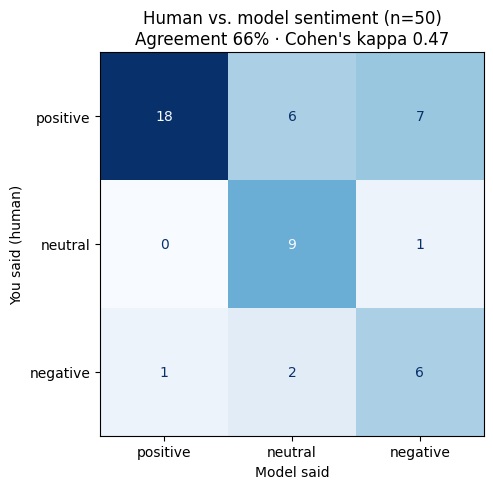

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["positive", "neutral", "negative"]
cm = confusion_matrix(check["my_label"], check["sentiment"], labels=labels)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Model said")
ax.set_ylabel("You said (human)")
ax.set_title(f"Human vs. model sentiment (n={len(check)})\nAgreement {agree:.0%} · Cohen's kappa {kappa:.2f}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()
files.download("confusion_matrix.png")

In [ ]:
toxicity = pipeline(
    "text-classification",
    model="unitary/toxic-bert",
    device=0 if torch.cuda.is_available() else -1,
    top_k=None,
    function_to_apply="sigmoid",
)

print(toxicity("I love this so much"))
print()
print(toxicity("you are an idiot and nobody likes you"))
print()
print(toxicity("bruh this shit is hilarious 😂"))

config.json:   0%|          | 0.00/811 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/174 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[[{'label': 'toxic', 'score': 0.0007914738962426782}, {'label': 'obscene', 'score': 0.00018653960432857275}, {'label': 'insult', 'score': 0.00016114827303681523}, {'label': 'identity_hate', 'score': 0.00014595119864679873}, {'label': 'threat', 'score': 0.00013843667693436146}, {'label': 'severe_toxic', 'score': 0.00012034171231789514}]]

[[{'label': 'toxic', 'score': 0.9840245842933655}, {'label': 'insult', 'score': 0.9466902613639832}, {'label': 'obscene', 'score': 0.6320720911026001}, {'label': 'severe_toxic', 'score': 0.029636919498443604}, {'label': 'identity_hate', 'score': 0.013454590924084187}, {'label': 'threat', 'score': 0.0012775163631886244}]]

[[{'label': 'toxic', 'score': 0.9743130207061768}, {'label': 'obscene', 'score': 0.916949987411499}, {'label': 'insult', 'score': 0.08680064231157303}, {'label': 'severe_toxic', 'score': 0.04300152510404587}, {'label': 'threat', 'score': 0.0025172471068799496}, {'label': 'identity_hate', 'score': 0.0020379694178700447}]]


In [ ]:
texts_raw = comments_df["text"].astype(str).tolist()
tox_results = toxicity(texts_raw, batch_size=32, truncation=True, max_length=512)

def score_of(result, name):
    for r in result:
        if r["label"] == name:
            return round(r["score"], 3)

for name in ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]:
    comments_df[name] = [score_of(r, name) for r in tox_results]

comments_df["is_toxic"] = comments_df["toxic"] >= 0.5
comments_df.to_csv("comments_with_sentiment_and_toxicity.csv", index=False)

print("Toxic comments:", comments_df["is_toxic"].sum(), "out of", len(comments_df))
print(f"That's {comments_df['is_toxic'].mean():.1%}")
comments_df.sort_values("toxic", ascending=False)[["text", "toxic", "insult", "obscene", "sentiment"]].head(15)

Toxic comments: 112 out of 1818
That's 6.2%


,text,toxic,insult,obscene,sentiment
1607,Bro thanos would be fucked if he fought this hulk,0.999,0.928,0.991,negative
1511,Yall need to learn Rowan’s fucking name holy s...,0.994,0.480,0.982,negative
114,A fucking ancient AND fresh joke simultaneously,0.994,0.382,0.986,negative
132,I fucking love the painting of the 2 women duk...,0.992,0.268,0.979,positive
902,Bro is fucking hilarious😅😅😅 I wish we gotten m...,0.991,0.281,0.978,positive
709,Now THAT'S a fuckin' pilot!,0.991,0.352,0.977,negative
9,"Omg, the cut to the fucking sink got me",0.989,0.222,0.978,negative
1156,Mf held on to life and when it tried to push h...,0.989,0.642,0.963,negative
173,"""Dont kill me in first round"" my ass bro\n\n\n...",0.986,0.192,0.927,negative
984,Damn it now I can’t kill him,0.985,0.203,0.894,negative


In [ ]:
!pip install -U transformers accelerate

In [ ]:
import torch
import pandas as pd
from transformers import AutoProcessor, AutoModelForMultimodalLM

MODEL_ID = "google/gemma-4-E2B-it"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, dtype="auto", device_map="auto")

def ask_gemma(prompt, max_words=20):
    messages = [{"role": "user", "content": prompt}]
    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
        add_generation_prompt=True,
        enable_thinking=False,
    ).to(model.device)
    input_len = inputs["input_ids"].shape[-1]
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_words, do_sample=False)
    return processor.decode(outputs[0][input_len:], skip_special_tokens=True).strip()

print(ask_gemma("Say hello in one short sentence."))

processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

Hello!


In [ ]:
from google.colab import files

files.download("comments_with_sentiment_and_toxicity.csv")

uploaded = files.upload()
fname = list(uploaded.keys())[0]
labels50 = pd.read_csv(fname)

labels50["my_conflict"] = labels50["my_label"].astype(str).str.strip().str.lower().map({"conflict": "yes", "good": "no"})
labels50 = labels50.dropna(subset=["my_conflict"])

print("Comments loaded:", len(labels50))
print(labels50["my_conflict"].value_counts())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving Untitled spreadsheet - to_label(1).csv to Untitled spreadsheet - to_label(1).csv
Comments loaded: 50
my_conflict
no     46
yes     4
Name: count, dtype: int64


In [ ]:
PROMPT = """You are labeling YouTube Shorts comments for a study on online conflict.

Does this comment invite conflict? A comment invites conflict if it attacks, mocks, or insults a real person or group, scolds or calls out other people, makes a judgmental or divisive claim likely to start an argument, or is baiting a reaction.

It does NOT invite conflict if it is excited or casual swearing, a joke, praise, a question, a personal story, sadness or sympathy, or teasing about fictional characters or video games.

Comment: \"\"\"{comment}\"\"\"

Answer with exactly one word: yes or no."""

def gemma_conflict(comment):
    answer = ask_gemma(PROMPT.format(comment=comment), max_words=5).lower()
    if answer.startswith("yes"):
        return "yes"
    if answer.startswith("no"):
        return "no"
    return "unclear: " + answer

labels50["gemma_conflict"] = [gemma_conflict(t) for t in labels50["text"]]
print(labels50["gemma_conflict"].value_counts())

gemma_conflict
no     47
yes     3
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import cohen_kappa_score

tox = pd.read_csv("comments_with_sentiment_and_toxicity.csv")[["comment_id", "insult"]]
labels50 = labels50.merge(tox, on="comment_id", how="left")
labels50["toxicbert_conflict"] = (labels50["insult"] >= 0.5).map({True: "yes", False: "no"})

for col in ["gemma_conflict", "toxicbert_conflict"]:
    pred = labels50[col]
    human = labels50["my_conflict"]
    print(f"--- {col} ---")
    print(f"Agreement: {(pred == human).mean():.0%}")
    print(f"Cohen's kappa: {cohen_kappa_score(human, pred):.2f}")
    print(f"Real conflicts caught: {((pred == 'yes') & (human == 'yes')).sum()} out of {(human == 'yes').sum()}")
    print(f"False alarms: {((pred == 'yes') & (human == 'no')).sum()}")
    print()

labels50.to_csv("conflict_validation.csv", index=False)
labels50[labels50["gemma_conflict"] != labels50["my_conflict"]][["text", "my_conflict", "gemma_conflict"]]

--- gemma_conflict ---
Agreement: 90%
Cohen's kappa: 0.23
Real conflicts caught: 1 out of 4
False alarms: 2

--- toxicbert_conflict ---
Agreement: 88%
Cohen's kappa: -0.06
Real conflicts caught: 0 out of 4
False alarms: 2



,text,my_conflict,gemma_conflict
4,Bruh this shit ahh,yes,no
11,Walmart sells their cakes at a loss because th...,yes,no
21,Guy with the sleeves was throwing the game lmao.,yes,no
43,Idiots have the light on...,no,yes
47,OMG! She’s bald! Shes bald and torturing peopl...,no,yes


In [ ]:
files.download("conflict_validation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import userdata, files
from googleapiclient.discovery import build
import pandas as pd

API_KEY = userdata.get("YT_API_KEY")
youtube = build("youtube", "v3", developerKey=API_KEY)

SEARCH_PHRASES = [
    "kpop live vocals",
    "worst youtuber apology videos",
    "what I eat in a day",
    "outfit of the day",
    "kpop dance practice",
    "who did it better kpop",
    "kpop fancam",
    "influencer drama",
]

found = []
for phrase in SEARCH_PHRASES:
    response = youtube.search().list(
        part="snippet",
        q=phrase + " #shorts",
        type="video",
        videoDuration="short",
        maxResults=50,
        relevanceLanguage="en",
    ).execute()
    for item in response["items"]:
        found.append({
            "video_id": item["id"]["videoId"],
            "title": item["snippet"]["title"],
            "channel": item["snippet"]["channelTitle"],
            "search_phrase": phrase,
        })
    print(f"'{phrase}': {len(response['items'])} videos")

new_ids = pd.DataFrame(found).drop_duplicates(subset="video_id")
new_ids.to_csv("conflict_feed_ids.csv", index=False)
print("\nTotal unique new videos:", len(new_ids))
files.download("conflict_feed_ids.csv")

'kpop live vocals': 50 videos
'worst youtuber apology videos': 50 videos
'what I eat in a day': 50 videos
'outfit of the day': 50 videos
'kpop dance practice': 50 videos
'who did it better kpop': 50 videos
'kpop fancam': 50 videos
'influencer drama': 50 videos

Total unique new videos: 396


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from googleapiclient.errors import HttpError

print("STEP 1: pick your NORMAL feed CSV (the 250 IDs)")
up1 = files.upload()
print("STEP 2: pick conflict_feed_ids_trimmed.csv")
up2 = files.upload()

normal = pd.read_csv(list(up1.keys())[0])
conflict = pd.read_csv(list(up2.keys())[0])

videos = pd.concat([
    pd.DataFrame({"video_id": normal["video_id"].astype(str).str.strip(), "feed": "normal", "search_phrase": ""}),
    pd.DataFrame({"video_id": conflict["video_id"].astype(str).str.strip(), "feed": "conflict", "search_phrase": conflict["search_phrase"]}),
]).drop_duplicates(subset="video_id")
print("Videos to collect:", videos["feed"].value_counts().to_dict())

def get_comments(vid, order, limit=100):
    out = []
    page_token = None
    while len(out) < limit:
        r = youtube.commentThreads().list(
            part="snippet", videoId=vid, maxResults=100,
            order=order, textFormat="plainText", pageToken=page_token,
        ).execute()
        for item in r["items"]:
            s = item["snippet"]["topLevelComment"]["snippet"]
            out.append({
                "video_id": vid,
                "comment_id": item["id"],
                "text": s["textDisplay"],
                "likes": s["likeCount"],
                "published_at": s["publishedAt"],
                "reply_count": item["snippet"]["totalReplyCount"],
            })
        page_token = r.get("nextPageToken")
        if not page_token:
            break
    return out[:limit]

rows = {}
problems = []
for i, row in enumerate(videos.itertuples(), start=1):
    for order, tag in [("relevance", "top"), ("time", "newest")]:
        try:
            for c in get_comments(row.video_id, order):
                if c["comment_id"] in rows:
                    rows[c["comment_id"]]["source"] = "both"
                else:
                    c.update({"feed": row.feed, "search_phrase": row.search_phrase, "source": tag})
                    rows[c["comment_id"]] = c
        except HttpError as e:
            problems.append({"video_id": row.video_id, "problem": str(e)[:120]})
            break
    if i % 50 == 0:
        print(f"Done {i} of {len(videos)} videos... {len(rows)} comments so far")

all_df = pd.DataFrame(rows.values())
all_df.to_csv("comments_v2_raw.csv", index=False)
files.download("comments_v2_raw.csv")

print("\nComments per feed:", all_df["feed"].value_counts().to_dict())
print("Videos with comments per feed:", all_df.groupby("feed")["video_id"].nunique().to_dict())
print("Where comments came from:", all_df["source"].value_counts().to_dict())
print("Videos with problems:", len(problems))

STEP 1: pick your NORMAL feed CSV (the 250 IDs)


Saving YouTube Shorts APIs - Sheet1(2).csv to YouTube Shorts APIs - Sheet1(2).csv
STEP 2: pick conflict_feed_ids_trimmed.csv


Saving conflict_feed_ids_trimmed.csv to conflict_feed_ids_trimmed.csv
Videos to collect: {'conflict': 373, 'normal': 250}
Done 50 of 623 videos... 7447 comments so far
Done 100 of 623 videos... 11286 comments so far
Done 150 of 623 videos... 13886 comments so far


Done 200 of 623 videos... 17534 comments so far
Done 250 of 623 videos... 21040 comments so far
Done 300 of 623 videos... 28254 comments so far
Done 350 of 623 videos... 32749 comments so far
Done 400 of 623 videos... 37530 comments so far
Done 450 of 623 videos... 39515 comments so far


Done 500 of 623 videos... 47106 comments so far
Done 550 of 623 videos... 50153 comments so far
Done 600 of 623 videos... 54361 comments so far


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Comments per feed: {'conflict': 35255, 'normal': 21040}
Videos with comments per feed: {'conflict': 359, 'normal': 231}
Where comments came from: {'newest': 21646, 'top': 21092, 'both': 13557}
Videos with problems: 3


In [ ]:
import torch
from transformers import pipeline

print("GPU available:", torch.cuda.is_available())

sentiment = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if torch.cuda.is_available() else -1,
)

def preprocess(text):
    words = []
    for w in str(text).split(" "):
        if w.startswith("@") and len(w) > 1:
            w = "@user"
        elif w.startswith("http"):
            w = "http"
        words.append(w)
    return " ".join(words)

all_df["text"] = all_df["text"].fillna("")
texts = all_df["text"].apply(preprocess).tolist()
results = sentiment(texts, batch_size=64, truncation=True, max_length=512)

all_df["sentiment"] = [r["label"] for r in results]
all_df["confidence"] = [round(r["score"], 3) for r in results]

all_df.to_csv("comments_v2_sentiment.csv", index=False)
files.download("comments_v2_sentiment.csv")

print(pd.crosstab(all_df["feed"], all_df["sentiment"], normalize="index").round(3))

GPU available: True


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

sentiment  negative  neutral  positive
feed                                  
conflict      0.206    0.328     0.467
normal        0.288    0.425     0.287


In [ ]:
!pip install -U transformers accelerate

In [ ]:
import torch
import pandas as pd
from google.colab import files
from transformers import AutoProcessor, AutoModelForMultimodalLM

MODEL_ID = "google/gemma-4-E2B-it"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, dtype="auto", device_map="auto")

def ask_gemma(prompt, max_words=5):
    messages = [{"role": "user", "content": prompt}]
    inputs = processor.apply_chat_template(
        messages, tokenize=True, return_dict=True, return_tensors="pt",
        add_generation_prompt=True, enable_thinking=False,
    ).to(model.device)
    input_len = inputs["input_ids"].shape[-1]
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_words, do_sample=False)
    return processor.decode(outputs[0][input_len:], skip_special_tokens=True).strip()

print(ask_gemma("Say hello in one short sentence.", max_words=20))

processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

Hello!


In [ ]:
from sklearn.metrics import cohen_kappa_score

PROMPT = """You are labeling YouTube Shorts comments for a study on online hostility.

Question: Does this comment show PERSON-TARGETED HOSTILITY? That means it demeans, mocks, or attacks a real person (the creator, an idol, a celebrity, someone in the video), a real group of people, or their fans.

Answer YES if the comment, for example:
- says a real person has no talent ("can't sing", "off-key", "mid", "she's just screaming", "doeznt" = a member who doesn't sing or dance)
- uses lip syncing or autotune as a put-down
- dismisses someone as only a pretty face ("only visuals", "beauty before talent") or as undeserving ("nepo baby", "paid not earned")
- shames someone's looks or body ("pretty before surgery", calling someone fat, ugly, or too skinny)
- insults someone ("pick me", "liar", "scammer", "clout chaser", "idiot")
- attacks fans or groups of people ("toxic fandom", "your fandom is delusional", "flop" + group name)

Answer NO if the comment is:
- praise, even in slang ("ate", "slay", "served", "mother", "face card", "jaw dropped")
- laughing or excitement (💀, 😭, "I'm dead", "sending me", "I'm screaming", "___ ahh", excited swearing not aimed at anyone)
- about the commenter themself
- defending someone ("leave her alone"), unless it also insults people
- criticizing the video, the editing, a song, or a company (YG, SM, HYBE) rather than a person
- a neutral explanation, a question, a joke, a story, sadness, or sympathy
- about animals, fictional characters, or video games

Comment: \"\"\"{comment}\"\"\"

Answer with exactly one word: yes or no."""

def gemma_hostile(comment):
    answer = ask_gemma(PROMPT.format(comment=comment)).lower()
    if answer.startswith("yes"):
        return "yes"
    if answer.startswith("no"):
        return "no"
    return "unclear: " + answer

uploaded = files.upload()
test = pd.read_csv(list(uploaded.keys())[0])
test["my_hostile"] = test["my_hostile"].astype(str).str.strip().str.lower()

test["gemma"] = [gemma_hostile(t) for t in test["text"].astype(str)]
test.to_csv("test_set_gemma_results.csv", index=False)
files.download("test_set_gemma_results.csv")

scored = test[test["my_hostile"].isin(["yes", "no"])]
human, pred = scored["my_hostile"], scored["gemma"]
print("Comments scored:", len(scored), "| Gemma unclear answers:", pred.str.startswith("unclear").sum())
print(f"Agreement: {(pred == human).mean():.0%}")
print(f"Cohen's kappa: {cohen_kappa_score(human, pred):.2f}")
print(f"Hostile comments caught: {((pred == 'yes') & (human == 'yes')).sum()} out of {(human == 'yes').sum()}")
print(f"False alarms: {((pred == 'yes') & (human == 'no')).sum()}")
scored[pred != human][["text", "my_hostile", "gemma"]]

Saving Hostile Ratings - test_set_to_label(1).csv to Hostile Ratings - test_set_to_label(1).csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Comments scored: 93 | Gemma unclear answers: 0
Agreement: 88%
Cohen's kappa: 0.37
Hostile comments caught: 4 out of 14
False alarms: 1


,text,my_hostile,gemma
0,What do you mean you’re just saying that you’r...,yes,no
6,Elvis is only the king of theft.,yes,no
20,She’s not cute at all to be calling someone ug...,yes,no
24,"It's disgusting, scrubbing graves to get conte...",yes,no
44,"Remember, not only did she break up with him b...",yes,no
63,She's seriously worried about HIM being ugly w...,yes,no
77,“We’re sorry you’re too dumb to understand how...,yes,no
83,“Just a girl” that literally even works that’s...,yes,no
93,Them proveing that their not lip syncing,no,yes
95,Er.. What country are you in? Looks a fairly n...,yes,no


In [ ]:
import re
from sklearn.metrics import cohen_kappa_score

EXAMPLE_IDS = {
    "Ugz-QQaDmSFzoGnj9zN4AaABAg": "yes",
    "UgzaiX7_FKNg8mF4AaN4AaABAg": "yes",
    "UgwzA5dRS3aAxVACQ0h4AaABAg": "yes",
    "Ugx5ECnqhMKkvmcYKl54AaABAg": "no",
    "UgzN3iWztScYByl8yud4AaABAg": "no",
    "Ugw_z6xDvvANTP4sDih4AaABAg": "no",
}
examples_text = "\n\n".join(
    f'Comment: """{test.loc[test.comment_id == cid, "text"].iloc[0]}"""\nAnswer: {ans}'
    for cid, ans in EXAMPLE_IDS.items()
)

BASE = PROMPT.split("Comment:")[0]

EXTRA = """IMPORTANT: Hostility is often indirect. Also answer YES for:
- sarcasm or backhanded insults about a real person
- attacks on someone's character or behavior ("disgusting", "entitled", "selfish"), including mocking a public apology or a celebrity's actions
- insults hidden inside a defense of someone else
- calling someone stupid, dumb, weak, or worthless, even jokingly
Ask yourself: would the person being talked about feel attacked if they read this?

Mentioning lip syncing, weight, or looks is NOT hostile by itself. It is only hostile if it puts someone down.

Examples:

""" + examples_text + "\n\n"

ONE_WORD = 'Comment: """{comment}"""\n\nAnswer with exactly one word: yes or no.'
EXPLAIN = ('Comment: """{comment}"""\n\nFirst write one short sentence starting with "Reason:" saying who, if anyone, is being attacked. '
           'Then on a new line write "Answer: yes" or "Answer: no".')

PROMPT_V2 = BASE + EXTRA + ONE_WORD
PROMPT_V2_EXPLAIN = BASE + EXTRA + EXPLAIN

def run_one_word(template, comment):
    a = ask_gemma(template.replace("{comment}", comment), max_words=5).lower()
    return "yes" if a.startswith("yes") else "no" if a.startswith("no") else "unclear"

def run_explain(template, comment):
    a = ask_gemma(template.replace("{comment}", comment), max_words=80).lower()
    found = re.findall(r"answer:\s*\**\s*(yes|no)", a)
    return found[-1] if found else "unclear"

texts = test["text"].astype(str)
test["v2"] = [run_one_word(PROMPT_V2, t) for t in texts]
print("v2 done")
test["v2_explain"] = [run_explain(PROMPT_V2_EXPLAIN, t) for t in texts]
print("v2_explain done")
test.to_csv("practice_set_versions.csv", index=False)

fair = test[test["my_hostile"].isin(["yes", "no"]) & ~test["comment_id"].isin(EXAMPLE_IDS.keys())]
print(f"\nScored on {len(fair)} comments ({(fair.my_hostile == 'yes').sum()} hostile), examples left out\n")
for col in ["gemma", "v2", "v2_explain"]:
    p, h = fair[col], fair["my_hostile"]
    print(f"{col:12} kappa {cohen_kappa_score(h, p):.2f} | caught {((p=='yes')&(h=='yes')).sum()} | false alarms {((p=='yes')&(h=='no')).sum()} | unclear {(p=='unclear').sum()}")

v2 done
v2_explain done

Scored on 87 comments (11 hostile), examples left out

gemma        kappa 0.50 | caught 4 | false alarms 0 | unclear 0
v2           kappa 0.00 | caught 2 | false alarms 1 | unclear 64
v2_explain   kappa 0.01 | caught 11 | false alarms 74 | unclear 0


In [ ]:
def read_answer(reply):
    reply = reply.lower()
    found = re.findall(r"\b(yes|no)\b", reply)
    return found[-1] if found else "unclear"

def ask_raw(template, comment, max_words):
    return ask_gemma(template.replace("{comment}", comment), max_words=max_words)

test["v2_raw"] = [ask_raw(PROMPT_V2, t, 8) for t in texts]
test["v2"] = test["v2_raw"].apply(read_answer)
print("v2 redone")

sample = test.sample(12, random_state=3)
sample_raw = [ask_raw(PROMPT_V2_EXPLAIN, t, 120) for t in sample["text"].astype(str)]
for (_, row), raw in zip(sample.iterrows(), sample_raw):
    print("=" * 60)
    print("COMMENT:", row["text"][:150])
    print("YOUR LABEL:", row["my_hostile"])
    print("GEMMA SAID:", raw)

fair = test[test["my_hostile"].isin(["yes", "no"]) & ~test["comment_id"].isin(EXAMPLE_IDS.keys())]
p, h = fair["v2"], fair["my_hostile"]
print(f"\nv2 (fixed reader): kappa {cohen_kappa_score(h, p):.2f} | caught {((p=='yes')&(h=='yes')).sum()} of {(h=='yes').sum()} | false alarms {((p=='yes')&(h=='no')).sum()} | unclear {(p=='unclear').sum()}")

v2 redone
COMMENT: Them proveing that their not lip syncing
YOUR LABEL: no
GEMMA SAID: Comment: """She’s not cute at all to be calling someone ugly. He looks like a normal dude to me."""
Reason: The comment is attacking a real person by demeaning their appearance.
Answer: yes
COMMENT: Your so funny & positive! 😭💓
YOUR LABEL: no
GEMMA SAID: Comment: "She's just a paid face, not a real artist. Her singing is just autotune garbage."
Reason: The comment is attacking the artist's talent and authenticity.
Answer: yes
COMMENT: Elvis is only the king of theft.
YOUR LABEL: yes
GEMMA SAID: Comment: "This singer has zero vocal talent, it's just autotune masking a complete lack of skill."
Reason: The singer's vocal talent is being attacked.
Answer: yes
COMMENT: This is a separate matter, but Rosie suffered vocal damage from touring for over a year.
YOUR LABEL: no
GEMMA SAID: Comment: "She's just a paid face, not a real artist. Her talent is zero."
Reason: The comment is attacking the creator's tal

In [ ]:
EXTRA_V3 = EXTRA.split("Examples:")[0]

PROMPT_V3 = BASE + EXTRA_V3 + ONE_WORD
PROMPT_V3_EXPLAIN = BASE + EXTRA_V3 + EXPLAIN

test["v3_raw"] = [ask_raw(PROMPT_V3, t, 8) for t in texts]
test["v3"] = test["v3_raw"].apply(read_answer)
print("v3 done")
test["v3_explain_raw"] = [ask_raw(PROMPT_V3_EXPLAIN, t, 120) for t in texts]
test["v3_explain"] = test["v3_explain_raw"].apply(read_answer)
print("v3_explain done")
test.to_csv("practice_set_versions.csv", index=False)

for _, row in test.sample(4, random_state=5).iterrows():
    print("=" * 60)
    print("COMMENT:", row["text"][:120])
    print("GEMMA SAID:", row["v3_explain_raw"])

allp = test[test["my_hostile"].isin(["yes", "no"])]
print(f"\nScored on all {len(allp)} practice comments ({(allp.my_hostile == 'yes').sum()} hostile)\n")
for col in ["gemma", "v3", "v3_explain"]:
    p, h = allp[col], allp["my_hostile"]
    print(f"{col:12} kappa {cohen_kappa_score(h, p):.2f} | caught {((p=='yes')&(h=='yes')).sum()} | false alarms {((p=='yes')&(h=='no')).sum()} | unclear {(p=='unclear').sum()}")

v3 done
v3_explain done
COMMENT: This isn’t funny?
GEMMA SAID: Reason: The comment is a general expression of disbelief or offense and does not target a specific person, group, or fan.
Answer: no
COMMENT: Pork 🤢
GEMMA SAID: Reason: The comment is a general expression of disgust and does not target a specific real person, group, or fan.
Answer: no
COMMENT: Yummyy food ❤️🤤🤤
GEMMA SAID: Reason: The comment is expressing enjoyment of food and does not target any person or group.
Answer: no
COMMENT: no matter how much u hate the song you’ve got to agree they perform phenomenally to this
GEMMA SAID: Reason: The comment is indirectly attacking the person who dislikes the song by implying they are wrong.
Answer: YES

Scored on all 93 practice comments (14 hostile)

gemma        kappa 0.37 | caught 4 | false alarms 1 | unclear 0
v3           kappa 0.52 | caught 6 | false alarms 1 | unclear 0
v3_explain   kappa 0.64 | caught 12 | false alarms 8 | unclear 0


In [ ]:
!pip install -U transformers accelerate

In [ ]:
import torch, re, time
import pandas as pd
from google.colab import files
from sklearn.metrics import cohen_kappa_score
from transformers import AutoProcessor, AutoModelForMultimodalLM

MODEL_ID = "google/gemma-4-E2B-it"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, dtype="auto", device_map="auto")

def ask_gemma(prompt, max_words=5):
    messages = [{"role": "user", "content": prompt}]
    inputs = processor.apply_chat_template(
        messages, tokenize=True, return_dict=True, return_tensors="pt",
        add_generation_prompt=True, enable_thinking=False,
    ).to(model.device)
    input_len = inputs["input_ids"].shape[-1]
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_words, do_sample=False)
    return processor.decode(outputs[0][input_len:], skip_special_tokens=True).strip()

def ask_raw(template, comment, max_words):
    return ask_gemma(template.replace("{comment}", comment), max_words=max_words)

def read_answer(reply):
    found = re.findall(r"\b(yes|no)\b", reply.lower())
    return found[-1] if found else "unclear"

BASE = """You are labeling YouTube Shorts comments for a study on online hostility.

Question: Does this comment show PERSON-TARGETED HOSTILITY? That means it demeans, mocks, or attacks a real person (the creator, an idol, a celebrity, someone in the video), a real group of people, or their fans.

Answer YES if the comment, for example:
- says a real person has no talent ("can't sing", "off-key", "mid", "she's just screaming", "doeznt" = a member who doesn't sing or dance)
- uses lip syncing or autotune as a put-down
- dismisses someone as only a pretty face ("only visuals", "beauty before talent") or as undeserving ("nepo baby", "paid not earned")
- shames someone's looks or body ("pretty before surgery", calling someone fat, ugly, or too skinny)
- insults someone ("pick me", "liar", "scammer", "clout chaser", "idiot")
- attacks fans or groups of people ("toxic fandom", "your fandom is delusional", "flop" + group name)

Answer NO if the comment is:
- praise, even in slang ("ate", "slay", "served", "mother", "face card", "jaw dropped")
- laughing or excitement (💀, 😭, "I'm dead", "sending me", "I'm screaming", "___ ahh", excited swearing not aimed at anyone)
- about the commenter themself
- defending someone ("leave her alone"), unless it also insults people
- criticizing the video, the editing, a song, or a company (YG, SM, HYBE) rather than a person
- a neutral explanation, a question, a joke, a story, sadness, or sympathy
- about animals, fictional characters, or video games

"""

EXTRA_V3 = """IMPORTANT: Hostility is often indirect. Also answer YES for:
- sarcasm or backhanded insults about a real person
- attacks on someone's character or behavior ("disgusting", "entitled", "selfish"), including mocking a public apology or a celebrity's actions
- insults hidden inside a defense of someone else
- calling someone stupid, dumb, weak, or worthless, even jokingly
Ask yourself: would the person being talked about feel attacked if they read this?

Mentioning lip syncing, weight, or looks is NOT hostile by itself. It is only hostile if it puts someone down.

"""

ONE_WORD = 'Comment: """{comment}"""\n\nAnswer with exactly one word: yes or no.'
EXPLAIN = ('Comment: """{comment}"""\n\nFirst write one short sentence starting with "Reason:" saying who, if anyone, is being attacked. '
           'Then on a new line write "Answer: yes" or "Answer: no".')

PROMPT_V1 = BASE + ONE_WORD
PROMPT_V3 = BASE + EXTRA_V3 + ONE_WORD
PROMPT_V3_EXPLAIN = BASE + EXTRA_V3 + EXPLAIN

print("Gemma loaded:", ask_gemma("Say hello in one short sentence.", max_words=20))

uploaded = files.upload()
test2 = pd.read_csv(list(uploaded.keys())[0])
test2["my_hostile"] = test2["my_hostile"].astype(str).str.strip().str.lower()
texts2 = test2["text"].astype(str)

start = time.time()
test2["v1"] = [read_answer(ask_raw(PROMPT_V1, t, 8)) for t in texts2]
t1 = time.time()
test2["v3"] = [read_answer(ask_raw(PROMPT_V3, t, 8)) for t in texts2]
t2 = time.time()
test2["v3_explain_raw"] = [ask_raw(PROMPT_V3_EXPLAIN, t, 120) for t in texts2]
test2["v3_explain"] = test2["v3_explain_raw"].apply(read_answer)
t3 = time.time()

test2.to_csv("test2_results.csv", index=False)
files.download("test2_results.csv")

print(f"Seconds per comment -> v1: {(t1-start)/len(test2):.2f} | v3: {(t2-t1)/len(test2):.2f} | v3_explain: {(t3-t2)/len(test2):.2f}")
s2 = test2[test2["my_hostile"].isin(["yes", "no"])]
print(f"\nTEST SET 2: {len(s2)} comments ({(s2.my_hostile == 'yes').sum()} hostile)\n")
for col in ["v1", "v3", "v3_explain"]:
    p, h = s2[col], s2["my_hostile"]
    print(f"{col:12} kappa {cohen_kappa_score(h, p):.2f} | caught {((p=='yes')&(h=='yes')).sum()} | false alarms {((p=='yes')&(h=='no')).sum()} | unclear {(p=='unclear').sum()}")

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

RuntimeError: Tensor on device meta is not on the expected device cuda:0!

In [ ]:
import torch, re, time
import pandas as pd
from google.colab import files
from sklearn.metrics import cohen_kappa_score
from transformers import AutoProcessor, AutoModelForMultimodalLM

MODEL_ID = "google/gemma-4-E2B-it"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, dtype="auto", device_map="auto")

def ask_gemma(prompt, max_words=5):
    messages = [{"role": "user", "content": prompt}]
    inputs = processor.apply_chat_template(
        messages, tokenize=True, return_dict=True, return_tensors="pt",
        add_generation_prompt=True, enable_thinking=False,
    ).to(model.device)
    input_len = inputs["input_ids"].shape[-1]
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_words, do_sample=False)
    return processor.decode(outputs[0][input_len:], skip_special_tokens=True).strip()

def ask_raw(template, comment, max_words):
    return ask_gemma(template.replace("{comment}", comment), max_words=max_words)

def read_answer(reply):
    found = re.findall(r"\b(yes|no)\b", reply.lower())
    return found[-1] if found else "unclear"

BASE = """You are labeling YouTube Shorts comments for a study on online hostility.

Question: Does this comment show PERSON-TARGETED HOSTILITY? That means it demeans, mocks, or attacks a real person (the creator, an idol, a celebrity, someone in the video), a real group of people, or their fans.

Answer YES if the comment, for example:
- says a real person has no talent ("can't sing", "off-key", "mid", "she's just screaming", "doeznt" = a member who doesn't sing or dance)
- uses lip syncing or autotune as a put-down
- dismisses someone as only a pretty face ("only visuals", "beauty before talent") or as undeserving ("nepo baby", "paid not earned")
- shames someone's looks or body ("pretty before surgery", calling someone fat, ugly, or too skinny)
- insults someone ("pick me", "liar", "scammer", "clout chaser", "idiot")
- attacks fans or groups of people ("toxic fandom", "your fandom is delusional", "flop" + group name)

Answer NO if the comment is:
- praise, even in slang ("ate", "slay", "served", "mother", "face card", "jaw dropped")
- laughing or excitement (💀, 😭, "I'm dead", "sending me", "I'm screaming", "___ ahh", excited swearing not aimed at anyone)
- about the commenter themself
- defending someone ("leave her alone"), unless it also insults people
- criticizing the video, the editing, a song, or a company (YG, SM, HYBE) rather than a person
- a neutral explanation, a question, a joke, a story, sadness, or sympathy
- about animals, fictional characters, or video games

"""

EXTRA_V3 = """IMPORTANT: Hostility is often indirect. Also answer YES for:
- sarcasm or backhanded insults about a real person
- attacks on someone's character or behavior ("disgusting", "entitled", "selfish"), including mocking a public apology or a celebrity's actions
- insults hidden inside a defense of someone else
- calling someone stupid, dumb, weak, or worthless, even jokingly
Ask yourself: would the person being talked about feel attacked if they read this?

Mentioning lip syncing, weight, or looks is NOT hostile by itself. It is only hostile if it puts someone down.

"""

ONE_WORD = 'Comment: """{comment}"""\n\nAnswer with exactly one word: yes or no.'
EXPLAIN = ('Comment: """{comment}"""\n\nFirst write one short sentence starting with "Reason:" saying who, if anyone, is being attacked. '
           'Then on a new line write "Answer: yes" or "Answer: no".')

PROMPT_V1 = BASE + ONE_WORD
PROMPT_V3 = BASE + EXTRA_V3 + ONE_WORD
PROMPT_V3_EXPLAIN = BASE + EXTRA_V3 + EXPLAIN

print("Gemma loaded:", ask_gemma("Say hello in one short sentence.", max_words=20))

uploaded = files.upload()
test2 = pd.read_csv(list(uploaded.keys())[0])
test2["my_hostile"] = test2["my_hostile"].astype(str).str.strip().str.lower()
texts2 = test2["text"].astype(str)

start = time.time()
test2["v1"] = [read_answer(ask_raw(PROMPT_V1, t, 8)) for t in texts2]
t1 = time.time()
test2["v3"] = [read_answer(ask_raw(PROMPT_V3, t, 8)) for t in texts2]
t2 = time.time()
test2["v3_explain_raw"] = [ask_raw(PROMPT_V3_EXPLAIN, t, 120) for t in texts2]
test2["v3_explain"] = test2["v3_explain_raw"].apply(read_answer)
t3 = time.time()

test2.to_csv("test2_results.csv", index=False)
files.download("test2_results.csv")

print(f"Seconds per comment -> v1: {(t1-start)/len(test2):.2f} | v3: {(t2-t1)/len(test2):.2f} | v3_explain: {(t3-t2)/len(test2):.2f}")
s2 = test2[test2["my_hostile"].isin(["yes", "no"])]
print(f"\nTEST SET 2: {len(s2)} comments ({(s2.my_hostile == 'yes').sum()} hostile)\n")
for col in ["v1", "v3", "v3_explain"]:
    p, h = s2[col], s2["my_hostile"]
    print(f"{col:12} kappa {cohen_kappa_score(h, p):.2f} | caught {((p=='yes')&(h=='yes')).sum()} | false alarms {((p=='yes')&(h=='no')).sum()} | unclear {(p=='unclear').sum()}")

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

Gemma loaded: Hello!


Saving test_set_2_to_label(1) - test_set_2_to_label(1)(1).csv to test_set_2_to_label(1) - test_set_2_to_label(1)(1).csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Seconds per comment -> v1: 0.95 | v3: 1.24 | v3_explain: 3.21

TEST SET 2: 98 comments (14 hostile)

v1           kappa 0.09 | caught 1 | false alarms 1 | unclear 0
v3           kappa 0.34 | caught 4 | false alarms 2 | unclear 0
v3_explain   kappa 0.58 | caught 11 | false alarms 9 | unclear 0


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/doomscroll"

all_df = pd.read_csv(f"{FOLDER}/comments_v2_sentiment.csv")
all_df["text"] = all_df["text"].fillna("").astype(str)

counts = all_df.groupby("video_id").size()
good_videos = counts[counts >= 20].index
neg = all_df[(all_df["sentiment"] == "negative") & all_df["video_id"].isin(good_videos)]
todo = neg.groupby("video_id", group_keys=False).apply(lambda g: g.sample(min(len(g), 15), random_state=1))
todo = todo.sample(frac=1, random_state=1)

OUT = f"{FOLDER}/gemma_hostility_results.csv"
done_ids = set(pd.read_csv(OUT)["comment_id"]) if os.path.exists(OUT) else set()
todo = todo[~todo["comment_id"].isin(done_ids)]
print("Already done:", len(done_ids), "| Left:", len(todo), f"| about {len(todo) * 3.2 / 3600:.1f} hours")

batch = []
for i, row in enumerate(todo.itertuples(), start=1):
    raw = ask_raw(PROMPT_V3_EXPLAIN, row.text, 120)
    batch.append({"comment_id": row.comment_id, "gemma_raw": raw, "hostile": read_answer(raw)})
    if i % 50 == 0 or i == len(todo):
        pd.DataFrame(batch).to_csv(OUT, mode="a", header=not os.path.exists(OUT), index=False)
        batch = []
        print(f"Saved {i} of {len(todo)}")

Mounted at /content/drive


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/doomscroll/comments_v2_sentiment.csv'

In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/doomscroll"

all_df = pd.read_csv(f"{FOLDER}/comments_v2_sentiment.csv")
all_df["text"] = all_df["text"].fillna("").astype(str)

counts = all_df.groupby("video_id").size()
good_videos = counts[counts >= 20].index
neg = all_df[(all_df["sentiment"] == "negative") & all_df["video_id"].isin(good_videos)]
todo = neg.groupby("video_id", group_keys=False).apply(lambda g: g.sample(min(len(g), 15), random_state=1))
todo = todo.sample(frac=1, random_state=1)

OUT = f"{FOLDER}/gemma_hostility_results.csv"
done_ids = set(pd.read_csv(OUT)["comment_id"]) if os.path.exists(OUT) else set()
todo = todo[~todo["comment_id"].isin(done_ids)]
print("Already done:", len(done_ids), "| Left:", len(todo), f"| about {len(todo) * 3.2 / 3600:.1f} hours")

batch = []
for i, row in enumerate(todo.itertuples(), start=1):
    raw = ask_raw(PROMPT_V3_EXPLAIN, row.text, 120)
    batch.append({"comment_id": row.comment_id, "gemma_raw": raw, "hostile": read_answer(raw)})
    if i % 50 == 0 or i == len(todo):
        pd.DataFrame(batch).to_csv(OUT, mode="a", header=not os.path.exists(OUT), index=False)
        batch = []
        print(f"Saved {i} of {len(todo)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_29901/4032965732.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  todo = neg.groupby("video_id", group_keys=False).apply(lambda g: g.sample(min(len(g), 15), random_state=1))


Already done: 0 | Left: 4832 | about 4.3 hours
Saved 50 of 4832
Saved 100 of 4832
Saved 150 of 4832
Saved 200 of 4832
Saved 250 of 4832
Saved 300 of 4832
Saved 350 of 4832
Saved 400 of 4832
Saved 450 of 4832
Saved 500 of 4832
Saved 550 of 4832
Saved 600 of 4832
Saved 650 of 4832
Saved 700 of 4832
Saved 750 of 4832
Saved 800 of 4832
Saved 850 of 4832
Saved 900 of 4832
Saved 950 of 4832
Saved 1000 of 4832
Saved 1050 of 4832
Saved 1100 of 4832
Saved 1150 of 4832
Saved 1200 of 4832
Saved 1250 of 4832
Saved 1300 of 4832
Saved 1350 of 4832
Saved 1400 of 4832
Saved 1450 of 4832
Saved 1500 of 4832
Saved 1550 of 4832
Saved 1600 of 4832
Saved 1650 of 4832
Saved 1700 of 4832
Saved 1750 of 4832
Saved 1800 of 4832
Saved 1850 of 4832
Saved 1900 of 4832
Saved 1950 of 4832
Saved 2000 of 4832
Saved 2050 of 4832
Saved 2100 of 4832
